# Practical Lab — Local AI with Ollama
**Running and Developing Local AI Applications** · PHD Student 

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8–16 GB RAM (NVIDIA GPU optional).

**Technologies:** Ollama · Python · REST API · `requests` · (optional) Open WebUI · a local LLM (Qwen, Gemma, Llama…)

> Ollama exposes a local HTTP service on `localhost:11434`, so the same model can be used from the terminal, Python, or any other software.


## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no per-token cost**.
Trade-off: local models may be **less capable or slower** than frontier cloud models, depending on hardware and model size.

## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [1]:
import sys, platform
print("Python  :", sys.version)
print("System  :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

Python  : 3.12.2 (tags/v3.12.2:6abddd9, Feb  6 2024, 21:26:36) [MSC v.1937 64 bit (AMD64)]
System  : Windows 11


In [2]:
!pip --version

pip 26.2.1 from C:\Users\assya\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip (python 3.12)



### Exercise 2 — Install Ollama
Download the installer for your OS from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`). Then verify:

In [4]:
!ollama --version

ollama version is 0.40.11


Make sure the Ollama service is running (the desktop app starts it automatically; otherwise run `ollama serve` in a separate terminal).

In [5]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("✅ Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("❌ Ollama is not running. Start it with `ollama serve` in a terminal.")

✅ Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model

In [6]:
MODEL  = "qwen3.5" 
MODEL2 = "gemma3"

In [7]:
!ollama pull {MODEL}

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest 
pulling f836f08f9211: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 921 MB                         
pulling 02d45dc1cf45: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 5.6 GB                         
pulling b507b9c2f6ca: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�   13 B                         
pulling 50cbab8a892c: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  11 KB                         
pulling 9371364b27a5: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�   65 B                         
pulling 08f9698c1116: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 

In [8]:
!ollama list

NAME              ID              SIZE      MODIFIED       
qwen3.5:latest    56671c2ab938    6.6 GB    14 seconds ago    
gemma3:latest     68ceab7e468a    3.4 GB    7 minutes ago     


### Exercise 4 — Run the model

In [9]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:
        payload["system"] = system
    if fmt:
        payload["format"] = fmt
    if images:
        payload["images"] = images
    if options:
        payload["options"] = options
    if think is not None:
        payload["think"] = think
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [11]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[27.4s]
Artificial intelligence is a branch of computer science focused on creating systems capable of performing tasks that typically require human intelligence. It involves developing algorithms and models that allow machines to learn from data, recognize patterns, and make decisions autonomously. Common applications include virtual assistants, self-driving cars, and recommendation engines used by online platforms. Advanced AI systems often use machine learning and deep neural networks to improve their accuracy as they process more information. The ultimate aim is to augment human capabilities, automate mundane tasks, and solve complex problems efficiently.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[33.1s]
Imagine having a really smart, super-fast computer brain that helps you learn new things without needing to be taught everything from scratch. That is basically **Artificial Intelligence**,

### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> 💡 Try it: disable Wi-Fi / unplug Ethernet and re-run the cell above.

**✍️ Your answer:**

**1** Yes. The model changes its language and level of detail depending on the audience. It can also give different answers to the same prompt because it generates text using probabilities.

**2** No. The code uses localhost:11434, which means Ollama runs on my own computer. No API key or cloud server is needed.

**3** On my computer. Ollama loads the model into memory and uses the GPU if available; otherwise, the CPU

**4** It still works because the model is already downloaded and runs locally. The internet is only needed to download models

## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [12]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[92.7s]
Good morning, class. Please take your seats and pull up a chair. Today, we are diving into a fundamental data structure and mathematical concept that underpins many algorithms in computer science: the **Directed Acyclic Graph (DAG)**.

Here is your lecture note summary for the session.

---

### 1. Definition
In graph theory, a **Directed Acyclic Graph (DAG)** is a specific type of directed graph with two distinct properties combined:

1.  **Directed:** The edges have a direction. If there is an edge from node $A$ to node $B$, we can traverse from $A$ to $B$, but not necessarily from $B$ to $A$. This direction represents a flow, dependency, or precedence (e.g., "Task A must be completed before Task B").
2.  **Acyclic:** The graph contains no cycles. You cannot start at a node and follow the directed edges to eventually return to that same node. Every path in a DAG is finite; the structure always terminates.

In simpler terms, a DAG is a network of dependencies where you can't g

In [13]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[55.1s]
Hello everyone, welcome to Class 101! Today we are talking about a very powerful data structure that you will use throughout your career: the **Directed Acyclic Graph**, or **DAG**.

Don't let the name scare you. Let’s break it down piece by piece using simple language and one clear example.

### What does "DAG" mean?

Think of the word as three words combined:

1.  **Graph:** Imagine a network map, like a subway system or a family tree. It has **nodes** (dots representing stations or people) and **edges** (lines connecting them).
2.  **Directed:** The lines have arrows pointing in a specific direction. If there is an arrow from Node A to Node B, it means you can go from A to B, but not back the other way. It implies a flow or a rule ("A must happen before B").
3.  **Acyclic:** "Cyclic" means circles (like a donut shape). So, **"acyclic"** means **no loops**. You cannot start at Node A and follow the arrows to eventually get back to Node A without stopping. Time only moves forw

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**✍️ Your answer:**

*Yes, the answers are different because the prompts have different instructions.*

*Role: Defines the model's voice and expertise.*

*Context: Helps the model understand the audience and topic.*

*Constraints: Control the length and complexity.*

*Output format: Organizes the answer as requested.*

*Specificity: Clear prompts give more precise answers, while vague prompts give more general answers.*

## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [14]:
!ollama list

NAME              ID              SIZE      MODIFIED       
qwen3.5:latest    56671c2ab938    6.6 GB    20 minutes ago    
gemma3:latest     68ceab7e468a    3.4 GB    27 minutes ago    


In [15]:
!ollama show {MODEL}

  Model
    architecture        qwen35             
    parameters          9.0B               
    context length      262144             
    embedding length    4096               
    quantization        Q4_K_M             
    requires            0.30.0             
    renderer            qwen3.5            
    parser              qwen3.5            
    template source     renderer_parser    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          456.01M    
    embedding length    1152       
    dimensions          4096       

  Parameters
    presence_penalty    1.5     
    temperature         1       
    top_k               20      
    top_p               0.95    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [16]:
!ollama ps

NAME              ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3.5:latest    56671c2ab938    5.6 GB    100% GPU     4096       llamacpp    4 minutes from now    


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [17]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:latest,6.55,qwen35,9.0B,Q4_K_M
1,gemma3:latest,3.35,gemma3,3.9B,Q4_K_M


Currently loaded in memory:


,name,size_GB,in_VRAM_GB,expires_at
0,qwen3.5:latest,5.61,5.61,2026-10-26T18:32:34.6565268Z


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**✍️ Your answer:**

*`ollama list` shows the models stored on disk (name, ID, size, modification date). `ollama ps` shows the models currently in memory (size, CPU/GPU split, context length, time before unloading).*

*`A downloaded model` is only a set of weight files that uses disk space.
`A loaded model` has its weights read into RAM / VRAM and is ready to answer; it uses memory, and the first request after a cold start pays a loading delay. Ollama unloads an idle model after the `keep_alive` period (5 minutes by default).*


## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [18]:
!ollama pull {MODEL2}
!ollama list

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest 
pulling f06e91e18fc7: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 2.5 GB                         
pulling 7a50f9607a47: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 851 MB                         
pulling e0a42594d802: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  358 B                         
pulling dd084c7d92a3: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–� 8.4 KB                         
pulling 3116c5225075: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�   77 B                         
pulling 4bf7b0a45f1a: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–�  144 B                         
verifying sha256 digest 
writing manifest â ‹ pulling manifest 
pulling f06e91e18fc7: 100% â–•â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ

NAME              ID              SIZE      MODIFIED               
gemma3:latest     68ceab7e468a    3.4 GB    Less than a second ago    
qwen3.5:latest    56671c2ab938    6.6 GB    23 minutes ago            


### Exercise 7 — Same prompt, different models

In [19]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\n⏱ {out['wall_s']:.1f}s")

MODEL: qwen3.5

```python
import math
from typing import Union

def is_prime(n: int) -> bool:
    """
    Determine whether a given integer is a prime number.

    A prime number is a natural number greater than 1 that has no positive
    divisors other than 1 and itself.

    Algorithm Explanation:
    - If n < 2, it is not prime by definition.
    - If n = 2 or n = 3, it is prime.
    - Exclude even numbers and multiples of 3 immediately.
    - Check potential divisors from 5 up to sqrt(n) in steps of 6,
      testing only forms 6k ± 1 (e.g., 5, 7, 11, 13, etc.).

    Time Complexity: O(√n)
    Space Complexity: O(1)

    Args:
        n (int): The integer to check.

    Returns:
        bool: True if n is prime, False otherwise.

    Raises:
        ValueError: If input is not an integer or is negative.
    """
    if not isinstance(n, int):
        raise TypeError("Input must be an integer")
    if n < 0:
        raise ValueError("Input must be non-negative")
    
    # Handle spec

Now fill in your evaluation (scores out of 5) and see the table:

In [20]:
scores = {
    MODEL:  {"Response quality /5": 5, "Code correctness /5": 4},
    MODEL2: {"Response quality /5": 4, "Code correctness /5": 4},
}

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5,24.3,5,4
1,gemma3,36.5,4,4


**Tip — test the generated code:** copy the function the model wrote into a cell and check it.

In [21]:
import re, inspect

def is_prime_reference(n: int) -> bool:
    if n < 2:
        return False
    if n < 4:
        return True
    if n % 2 == 0:
        return False
    i = 3
    while i * i <= n:
        if n % i == 0:
            return False
        i += 2
    return True

def extract_candidate(text):
    for block in re.findall(r"```(?:python)?\n(.*?)```", text, re.DOTALL):
        ns = {"__name__": "candidate"}
        try:
            exec(block, ns)
        except Exception:
            continue
        funcs = [v for v in ns.values() if inspect.isfunction(v)]
        named = [f for f in funcs if "prime" in f.__name__.lower()]
        if named or funcs:
            return (named or funcs)[0]
    return None

def passes(candidate):
    try:
        return all(bool(candidate(n)) == is_prime_reference(n) for n in range(-5, 2000))
    except Exception:
        return False

def has_all(text):
    return {
        "type hints": "->" in text,
        "docstring": '"""' in text or "\'\'\'" in text,
        "complexity": "O(" in text,
    }

rows = []
for m in (MODEL, MODEL2):
    text = results[m]["response"]
    fn = extract_candidate(text)
    out = results[m]
    rows.append({
        "Model": m,
        "Response time (s)": round(out["wall_s"], 1),
        "Tokens/s": round(out["eval_count"] / (out["eval_duration"] / 1e9), 1),
        "Function found": fn is not None,
        "Correct on -5..1999": passes(fn) if fn else False,
        **has_all(text),
    })
pd.DataFrame(rows)

,Model,Response time (s),Tokens/s,Function found,Correct on -5..1999,type hints,docstring,complexity
0,qwen3.5,24.3,37.0,True,False,True,True,True
1,gemma3,36.5,70.2,True,True,True,True,True


In [22]:
table = pd.DataFrame(rows)
fastest = table.loc[table["Tokens/s"].idxmax(), "Model"]
correct = table[table["Correct on -5..1999"]]["Model"].tolist()
print("Fastest model (tokens/s):", fastest)
print("Models with correct code:", correct if correct else "none")

Fastest model (tokens/s): gemma3
Models with correct code: ['gemma3']


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**✍️ Your answer:**

1. **Which model is faster?**  
   Qwen3.5 generates text faster, but Gemma3 had a shorter total response time.

2. **Which produces better code?**  
   Both scored 4/5 for code correctness. Qwen3.5 had a higher overall quality score.

3. **Which uses more memory?**  
   Qwen3.5 uses more model memory.

4. **Which would you choose for programming assistance?**  
   I would choose Qwen3.5 because it had a higher overall quality score.

5. **Is the largest model necessarily the best?**  
   No. The best model depends on quality, speed, and memory usage.

## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already available here):

In [23]:
!pip install -q requests


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [25]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Writing local_ai_lab/app.py


In [26]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [27]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing local_ai_lab/README.md


In [28]:
%env PYTHONIOENCODING=utf-8
!python local_ai_lab/app.py

env: PYTHONIOENCODING=utf-8
Recursion is a powerful programming technique where a function calls itself to solve a problem by breaking it down into smaller, similar subproblems. In Python, as in many languages, recursion must be carefully designed to avoid infinite loops. It works well for certain types of problemsâ€”especially those involving trees or nested structuresâ€”but can be inefficient or problematic if not used correctly.

---

### ðŸ”¹ Core Components of Recursion

Every recursive function needs two essential parts:

1. **Base Case** â€“ Stops the recursion by returning a final value when a condition is met.
2. **Recursive Case** â€“ Calls the function again with modified arguments to progress toward the base case.

Without both, you risk an infinite loop and eventually hit a "RecursionError".

---

### ðŸ”¹ Example 1: Factorial Function

```python
def factorial(n):
    if n == 0 or n == 1:  # Base case
        return 1
    else:                 # Recursive case
        retu

**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [29]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

Recursion is a fundamental programming concept where a function calls itself to solve a problem by breaking it down into smaller, similar subproblems until it reaches a base case that can be directly solved. Python supports this behavior natively, though it requires careful design to avoid infinite recursion and stack overflows.

---

## 1. What Is Recursion?

A recursive function has two essential components:

- **Base Case:** The condition under which the function stops calling itself.
- **Recursive Case:** The logic that reduces the problem and calls the function again with smaller inputs.
 ...

{'model': 'qwen3.5', 'created_at': '2026-10-26T19:00:11.9660791Z', 'done': True, 'done_reason': 'stop', 'total_duration': 34421220800, 'load_duration': 15555700, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 12, 'prompt_eval_duration': 358089000, 'eval_count': 1294, 'eval_duration': 33942858000, 'wall_s': 36.462799800000084}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works inside Jupyter (a prompt box appears). Type `exit` to stop.

In [65]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

chat_loop_stateless()  

Local AI Assistant
Type 'exit' to stop.



You:  what is machine learning ?



AI: At its simplest, **Machine Learning (ML)** is a branch of artificial intelligence that allows computer systems to learn and improve from experience without being explicitly programmed for every specific task.

Instead of writing code that says "if this happens, do that," you provide the system with **data**, and it learns the rules and patterns itself.

### How does it work?
Think of it like teaching a child:
*   **Traditional Programming:** You give the child a rulebook (e.g., "If a bird has wings, can fly, and feathers, it's a bird").
*   **Machine Learning:** You show the child hundreds of pictures of birds, dogs, and cats. Eventually, the child figures out how to tell them apart on their own without you giving them a rulebook.

### The Three Main Types of Machine Learning
1.  **Supervised Learning:** The system is trained on labeled data (input + correct output). It learns to make predictions based on examples.
    *   *Example:* Predicting house prices based on historical sal


You:  exit


In [31]:
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: **Machine learning (ML)** is a branch of artificial intelligence (AI) that enables computers to learn from data without being explicitly programmed for every specific task.

Instead of following rigid, hard-coded rules (like "if X happens, do Y"), a machine learning model identifies patterns in historical data and uses those patterns to make predictions or decisions when presented with new information.

### The Core Concept
Imagine teaching a child to recognize a cat:
*   **Traditional Programmi ...

You: Explain reinforcement learning.
AI: ### What is Reinforcement Learning?

**Reinforcement Learning (RL)** is a branch of Artificial Intelligence where an agent learns to make decisions by taking actions within an environment to maximize a cumulative reward. Unlike other forms of machine learning, the agent doesn't learn from a labeled dataset of correct answers; instead, it learns through **trial and error**.

### The Best Analogy: Training a Dog

Ima

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [32]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

chat_loop_memory()  


You:  my name is ahmed



AI: Hello Ahmed! It's nice to meet you. How can I help you today?



You:  what is my name ?



AI: Your name is Ahmed!



You:  exit


In [33]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Nice to meet you, Ahmed! How can I help you today? 

You: What is my name?
AI : Your name is Ahmed. 



In [34]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Nice to meet you, Ahmed! How can I help you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**✍️ Your answer:**

*The model remembers the name because the application sends the previous conversation with each request. The LLM is stateless, so it does not store memories itself. The conversation history is stored in a Python list and sent through the /api/chat endpoint. As the conversation grows, the prompt gets longer and may exceed the context window, so old messages may need to be shortened or summarized.*

---
#### Better approach: the `/api/chat` endpoint
Ollama also has a chat endpoint taking structured `messages` (with `system` / `user` / `assistant` roles) and applying the model's own chat template.

In [35]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Your name is Ahmed.


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [36]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[55.1s]
Here is a review of the `Calculator` class from a Senior Java Developer's perspective.

### 1. Potential Problems
*   **Division by Zero:** The method does not check if `b` is zero before performing division. This leads to undefined behavior in mathematics and crashes the JVM logic.
*   **Data Type Precision:** Using `int` implies integer arithmetic. If a developer passes values that result in a remainder, precision is lost (truncation). Depending on business requirements, this might be a functional bug.
*   **Lack of Documentation:** There are no Javadoc comments explaining the contract, edge cases, or expected behavior of the method. This makes maintenance difficult for other developers.
*   **Input Validation:** The method trusts the caller to provide valid inputs without explicit error reporting.

### 2. Runtime Errors
*   **`ArithmeticException`:** If `b` is passed as `0`, the JVM throws a `java.lang.ArithmeticException: / by zero`. Since this is an **Unchecked Exception**

In [37]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[24.6s]
# Bug Found: Setter Does Not Update Instance Variable

## The Issue

In the `setAge` method:

```java
public void setAge(int age) {
    age = age;  // ❌ BUG - parameter shadows instance variable!
}
```

This is a classic **parameter shadowing bug**. Because the local parameter `age` has the same name as the instance field, assigning `age = age` updates the parameter — not the object's field. Therefore, when you call:

```java
Student student = new Student("Alice");
student.setAge(25);
System.out.println(student.getAge()); // Output will always be undefined or 0 if default initialized
```

The `age` field never gets assigned, which breaks encapsulation and expected behavior.

## The Fix

Change the setter to assign to the instance variable explicitly:

```java
public void setAge(int age) {
    this.age = age;  // ✅ Correct - assigns to instance field
}
```

Or alternatively:

```java
public void setAge(int age) {
    this.age = age;
    if (age < 0 || age > 120) {
        throw 

> ✅ Expected finding: `age = age;` assigns the parameter to itself (variable shadowing); it should be `this.age = age;`. Did your model find it? Is `age` also never initialized in the constructor?

**Findings:**

1. `Calculator.divide`: Dividing by zero throws an `ArithmeticException`. Validate the input or document the exception.

2. `Student.setAge`: `age = age;` does not update the field. Use `this.age = age;`.

3. Constructor: `age` is not initialized, so it remains `0` by default.

## Part 11 — Structured Output
### Exercise 11
First, the naive approach: ask for "ONLY JSON" in the prompt.

In [38]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[4.6s]
```json
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "Low Risk (likely on a high-school GPA scale; low absences)",
  "recommendation": "Continue current academic habits and maintain consistent attendance."
}
```


In [39]:
import re

def extract_json(text):
    """Robust parsing: strip ```json fences and grab the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("❌ Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'Low Risk (likely on a high-school GPA scale; low absences)', 'recommendation': 'Continue current academic habits and maintain consistent attendance.'}


Better: use Ollama's **structured outputs** — pass a JSON Schema in `format` so the output is constrained to be valid.

In [40]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "low",
  "recommendation": "Continue current academic trajectory; monitor attendance to maintain performance."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

**✍️ Your answer:**

*Structured output is important because software needs predictable data. JSON Schema ensures the LLM returns data in the correct format, with the required fields and types. This makes it easier to validate and use the output in applications. However, correct formatting does not guarantee correct information.*

## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [41]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [42]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [43]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[3.2s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[2.7s]
Information not available.


**Observe:** the second answer should be *"Information not available."* — the model is grounded in the supplied document instead of its own training data. Does your model respect the instruction every time?

**✍️ Your observation:**

*In my test, the model answered the reinforcement learning question using the document. For "What is quantum computing?", it returned "Information not available."
This shows that the model can follow the instruction, but not always. Using a clear prompt can reduce hallucinations, but cannot eliminate them.*

## Part 13 — Mini-RAG
We create four documents, then build a **local retriever** that picks the most relevant one for a question and feeds it to the LLM.

In [44]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['ai.txt',
 'course.txt',
 'deep_learning.txt',
 'machine_learning.txt',
 'reinforcement_learning.txt']

In [45]:
%%writefile rag.py
import math
import os
import re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [46]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (3.1s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: GPUs
  (2.8s)

Q: What is supervised learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Supervised learning uses labelled data.
  (3.0s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (2.7s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the fundamental idea behind **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses different words than the document. Ollama can also compute embeddings locally (`ollama pull nomic-embed-text`).

In [47]:
EMBED_MODEL = "nomic-embed-text"
!ollama pull {EMBED_MODEL}

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names])
    q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

print(semantic_top("What hardware accelerates network training?", rag.load_documents("documents"), k=2))

pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest â ™ pulling manifest â ¹ pulling manifest â ¸ pulling manifest â ¼ pulling manifest â ´ pulling manifest â ¦ pulling manifest â § pulling manifest â ‡ pulling manifest â � pulling manifest â ‹ pulling manifest 
pulling 970aa74c0a90:   0% â–•                  â–� 124 KB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   0% â–•                  â–� 442 KB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   1% â–•                  â–� 1.7 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   1% â–•                  â–� 3.2 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   1% â–•                  â–� 3.3 MB/274 MB                  pulling manifest 
pulling 970aa74c0a90:   2% â–•      

[('deep_learning.txt', 0.6374555148433113), ('course.txt', 0.532473481254054)]


## Part 14 — Local AI Vision *(optional)*
Requires a **multimodal** model, e.g. `ollama pull gemma3` (vision-capable variants), `llava`, `qwen2.5vl`, `llama3.2-vision`.

In [48]:
VISION_MODEL = MODEL2
IMAGE_PATH = "image.jpg"

Okay, here’s an analysis of the image:

**1. Main Objects:**

*   **Woman:** The primary subject is a young woman with blonde, wavy hair and wearing glasses and a gray suit jacket over a white shirt.
*   **Laptop:** A silver laptop is open on a wooden table.
*   **Smartphone:** She is holding a blue smartphone to her ear.
*   **Coffee Cup:** A brown disposable coffee cup is in her hand.
*   **Wooden Table:** The laptop and other items rest on a wooden table.

**2. Environment:**

*   **Outdoor Setting:** The image is taken outdoors, likely in a patio or outdoor workspace.
*   **Wooden Structure:** There's a wooden structure (possibly a shed or small building) in the background.
*   **Wooden Chairs:** There are two wooden chairs visible in the background.
*   **Plants:** Some greenery can be seen in the background, suggesting a garden or planted area.

**3. Text Visible in the Image:**

*   There isn't any discernible text visible within the image.

**4. Possible Interpretation:**

The 

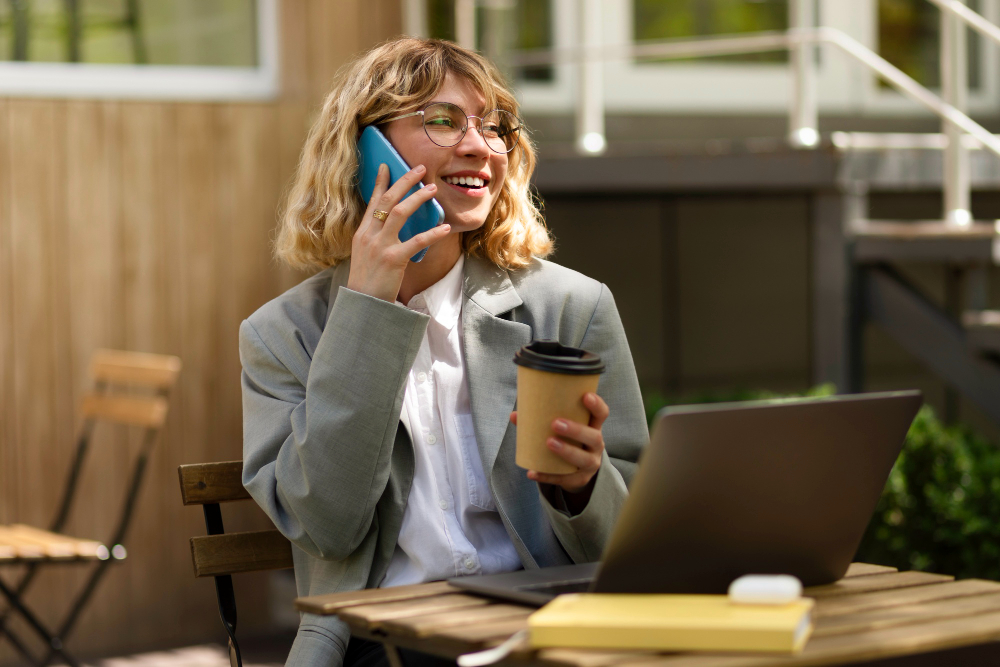

In [49]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\n⏱ {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"⚠️ Put an image named '{IMAGE_PATH}' next to this notebook, then re-run.")

### Questions
- Difference between an LLM and a multimodal model?
- What additional information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical-image preprocessing, surveillance analysis…)*

**✍️ Your answer:**

*An LLM processes text, while a multimodal model can process both text and images. It uses a vision encoder to understand images sent with the prompt. Local vision AI is useful for OCR, document analysis, and industrial inspection. It also helps protect privacy because images stay on the local machine.*

## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [50]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [51]:
%%writefile local-ai-web/app.py
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(debug=True)

Writing local-ai-web/app.py


In [52]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


Run it **from a terminal** (not inside the notebook):
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>. 🎉 You now have a complete local AI web application.

*(📸 Take a screenshot for your report: `screenshots/06_webapp.png`.)*

## Part 16 — Performance Benchmark
We measure: response time, model size, tokens generated, tokens/second, RAM and GPU consumption.

Ollama returns precise counters: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.

In [53]:
!pip install -q psutil


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [56]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = [5,4]
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5,6.55,5.61,5.61,35.13,128.89,767,8.40,97.3,5
1,gemma3,3.35,2.91,2.91,19.35,32.81,801,72.09,93.5,4


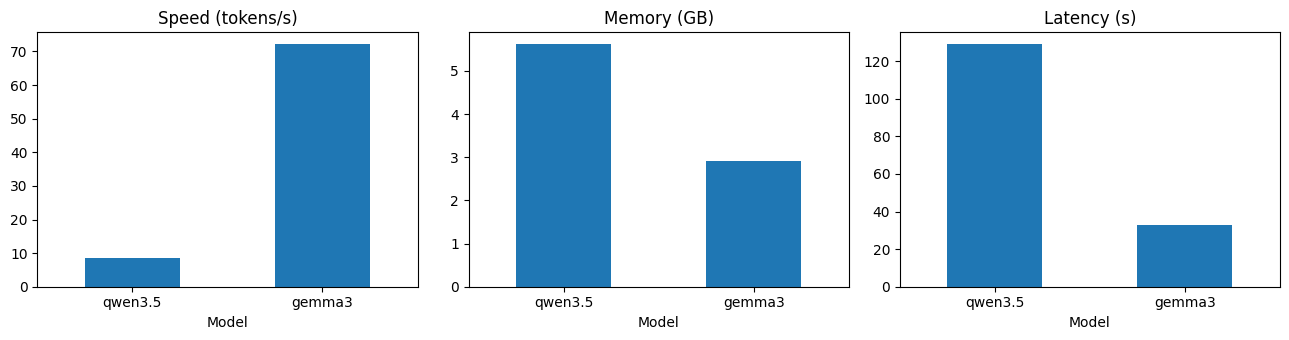

In [57]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model-size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
Local model selection should be based on **actual measurements on the target machine**, not just public benchmark rankings.

**✍️ Your discussion:**

*Qwen3.5 is larger (6.55 GB) and uses more memory (5.61 GB), but it generates 38.03 tokens/s. Gemma3 is smaller (3.35 GB), uses 2.91 GB of memory, and generates 20.63 tokens/s. Gemma3 loads more slowly (19.08 s vs 0.01 s), but its response time is shorter (58.82 s vs 141.86 s).*

*Therefore, Qwen3.5 is faster at generating tokens, while Gemma3 uses less memory and responds sooner in this test. The best model depends on the task, available hardware, and answer quality.*

## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a supplied course · uses local documents as knowledge · maintains conversation history · structured responses for selected questions · displays the answer · records response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final deliverable layout:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```

In [58]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [59]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [60]:
%%writefile LocalAI_Lab/source/app.py
import json
import os
import time

import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5")
DOC_DIR = os.path.join(os.path.dirname(os.path.abspath(__file__)), "..", "documents")
MAX_TURNS = 6

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = ([{"role": "system", "content": SYSTEM}]
                + history[-2 * MAX_TURNS:]
                + [{"role": "user", "content": user_msg}])

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    app.run(host="127.0.0.1", port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [61]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>🎓 FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "…thinking…");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "⚠️ " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `⏱ ${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "⚠️ " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [62]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

Flask web UI -> Ollama -> local LLM, with a TF-IDF retriever over `documents/`, conversation history, structured (JSON) answers and response-time display.

## Setup
```bash
ollama pull qwen3.5
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py
python chatbot.py
python benchmark.py qwen3.5 gemma3
```
Open http://127.0.0.1:5001 for the web interface. Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** launch it as a background process, send a few questions, then stop it.

In [66]:
import subprocess, sys

env = {**os.environ, "MODEL": MODEL, "PORT": "5001"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
time.sleep(3)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

for q, s in [("What is reinforcement learning?", False),
             ("And how is it different from supervised learning?", False),
             ("Summarize deep learning", True),
             ("What is quantum computing?", False)]:
    j = app_ask(q, s)
    print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
          f"   sources={j.get('sources')} | {j.get('seconds')}s | {j.get('tokens_per_s')} tok/s\n")

Q: What is reinforcement learning?
A: Reinforcement learning is a type of machine learning that learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward, aiming to learn a policy that maximises the cumulative reward.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] | 4.22s | 39.2 tok/s

Q: And how is it different from supervised learning?
A: Reinforcement learning learns through interaction with an environment using rewards and penalties, whereas supervised learning uses labelled data to learn a mapping from inputs to outputs.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_learning.txt', 'score': 1.06}] | 3.68s | 39.3 tok/s

Q: Summarize deep learning
A: {'difficulty': 'hard', 'key_points': ['uses artificial neural networks with many layers', 'learns representations from large amounts of data', 'Convolutional neural networks (

In [64]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


> 📸 Open <http://127.0.0.1:5001> in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report


**Q1.** What is Local AI?

*Local AI runs Ai models directly on my own computer instead of using a remote server*

**Q2.** Difference between a Cloud LLM and a Local LLM?

*Cloud LLM runs on a remote server and needs an internet connection . A local LLms runs on my own computer and can work offline*

**Q3.** What role does Ollama play?

*Ollama downloads , loads , and runs local AI models. Its also provides an API that applications can use to communicate with them*

**Q4.** What is model quantization?

Quantization reduces the precision of model weights to decrease memory usage and often improve inference speed, with a possible small loss in quality*

**Q5.** Why does model size affect memory consumption?

*larger models contain more parameters , which require more memory to store*

*additional memory is also needed to process inputs and generate responses*

**Q6.** Why can a smaller model sometimes be preferable?

*A smaller model uses less memory , load faster , and can run on less powerful hardware*

**Q7.** Advantages of local inference?

*local inference improves privacy , can work offline , avoid per-request cloud AP costs , and gives users more controle over their data*

**Q8.** Disadvantages of local inference?

*It requires suitable hardware , consumes local resources , and may provide lower quality or slower performance than a powerful clous model*

**Q9.** Explain the architecture of your Python application.

*the python application send a prompt to Ollama through its local API , Ollama runs the selected model and returns the generated reponse , which the application displays to the user*

**Q10.** Explain the role of the REST API.

*The REST API allows the Python application to communicate with Ollama by sending HTTP requests and receiving responses, usually in JSON format*

**Q11.** What is RAG?

*RAG (Retrieval-Augmented Generation) retrieves relevant information from external documents and provides it to the LLM to help generate more relevant and accurate answers*

**Q12.** Difference between an LLM and a multimodal LLM?

*An LLM processes text, while a multimodal LLM can process multiple types of data, such as text and images*

**Q13.** Compare two local models experimentally.

*Qwen3.5 uses more memory but generates tokens faster. Gemma3 is smaller and has a shorter response time in my measurements. The results show that model performance depends on memory usage, generation speed, and the task*

| Metric | Qwen3.5 | Gemma3 |
|---|---:|---:|
| Disk size (GB) | 6.55 | 3.35 |
| Loaded size (GB) | 5.61 | 2.91 |
| VRAM (GB) | 5.61 | 2.91 |
| Load time (s) | 0.01 | 19.08 |
| Response time (s) | 141.86 | 58.82 |
| Tokens/s | 38.03 | 20.63 |
| System RAM used (%) | 75.7 | 95.1 |

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

*I would choose Gemma3 because its loaded size is smaller (2.91 GB compared with 5.61 gb for Qwen3.5). However, my measurements show high system RAM usage (95.1%),so I would verify that enough memory remains available before deployment*

**Q15.** What security risks exist when exposing a local LLM server to a network?

*Ollama has no authentication by default, so unauthorized users may access the server if it is exposed. They could consume computer resources, access prompts or sensitive data, or misuse the service. Malicious documents may also contain prompt injections that manipulate the model. A firewall can restrict access , while a reverse proxy with authentication and TLS can help protect the server and encrypt communication*

## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [68]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/exit.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("✅" if os.path.exists(p) else "⬜ missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))

⬜ missing LocalAI_Lab/report.pdf
✅ LocalAI_Lab/README.md
✅ LocalAI_Lab/source/app.py
✅ LocalAI_Lab/source/chatbot.py
✅ LocalAI_Lab/source/rag.py
✅ LocalAI_Lab/source/benchmark.py
✅ LocalAI_Lab/screenshots/01_installation.png
✅ LocalAI_Lab/screenshots/02_model.png
✅ LocalAI_Lab/screenshots/03_chatbot.png
⬜ missing LocalAI_Lab/screenshots/exit.png
✅ LocalAI_Lab/screenshots/05_rag.png
✅ LocalAI_Lab/screenshots/06_webapp.png

Documents: ['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']
